# Feature Important (One Hot)
* Library
* Load Data
* Encoding
1. Logistic Regression
2. shap (Explainer)
* Result

# Library 

In [2]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
import shap
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\Asus\anaconda3\envs\ML\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Load Data 

In [3]:
def load_data(data):

    # columns
    columns = [
        "class", "cap-shape", "cap-surface", "cap-color", "bruises",
        "odor", "gill-attachment", "gill-spacing", "gill-size", "gill-color",
        "stalk-shape", "stalk-root", "stalk-surface-above-ring",
        "stalk-surface-below-ring", "stalk-color-above-ring",
        "stalk-color-below-ring", "veil-type", "veil-color",
        "ring-number", "ring-type", "spore-print-color", "population", "habitat"
    ]

    # Read Data 
    dataset = pd.read_csv(data, header=None, names=columns)

    return dataset

# Encoding

In [4]:
def encoding(dataset):
    
    X = dataset.drop('class', axis=1)
    y = LabelEncoder().fit_transform(dataset['class'])

    ohe = OneHotEncoder(drop='first', sparse_output=False)
    X_ohe = ohe.fit_transform(X)
    feature_names = ohe.get_feature_names_out(X.columns)

    return X_ohe, feature_names, y

# Logistic Regression

In [5]:
def logistic_Regression(X_ohe, feature_names, y):

    logreg = LogisticRegression(max_iter=2000, random_state=42)
    logreg.fit(X_ohe, y)

    coefficients = logreg.coef_[0]
    log_df = pd.DataFrame({
        'Feature': feature_names,
        'Coefficient': coefficients,
        'Abs_Coefficient': abs(coefficients)
    })

    log_df_sorted = log_df.sort_values(by='Abs_Coefficient', ascending=False).reset_index(drop=True)
    # (log_df_sorted.head(20))
    return logreg, log_df_sorted



In [28]:
def logistic_regression_chart(log_df_sorted):
    
    plt.figure(figsize=(10,8))
    sns.barplot(
        x='Abs_Coefficient',
        y='Feature',
        data=log_df_sorted.head(20)
    )
    plt.title("Top Features based on Logistic Regression (One-Hot)")
    plt.show()

# Sharp

In [29]:
def shap_explainer(X_ohe,feature_names, logreg):
    # Explainer برای Logistic Regression با داده One-Hot
    explainer = shap.Explainer(logreg, X_ohe, feature_names=feature_names)
    shap_values = explainer(X_ohe)

    return shap_values

In [30]:
def shap_chart(shap_values, n):
    # نمودار با اسم واقعی فیچرها
    shap.plots.bar(shap_values, max_display=n)

# Result

In [31]:
data = r"Dataset\Mushroom\agaricus-lepiota.data"

dataset = load_data(data)
X_ohe, feature_names, y = encoding(dataset)

logreg, log_df_sorted = logistic_Regression(X_ohe, feature_names, y)
shap_values = shap_explainer(X_ohe,feature_names, logreg)

In [32]:
log_df_sorted.head(20)

,Feature,Coefficient,Abs_Coefficient
0,spore-print-color_r,4.505689,4.505689
1,odor_n,-4.243207,4.243207
2,gill-size_n,3.598346,3.598346
3,odor_c,3.499054,3.499054
4,gill-spacing_w,-3.204946,3.204946
5,odor_f,3.167561,3.167561
6,odor_p,3.101152,3.101152
7,stalk-root_b,2.555222,2.555222
8,spore-print-color_u,-2.213352,2.213352
9,spore-print-color_n,-2.015410,2.015410


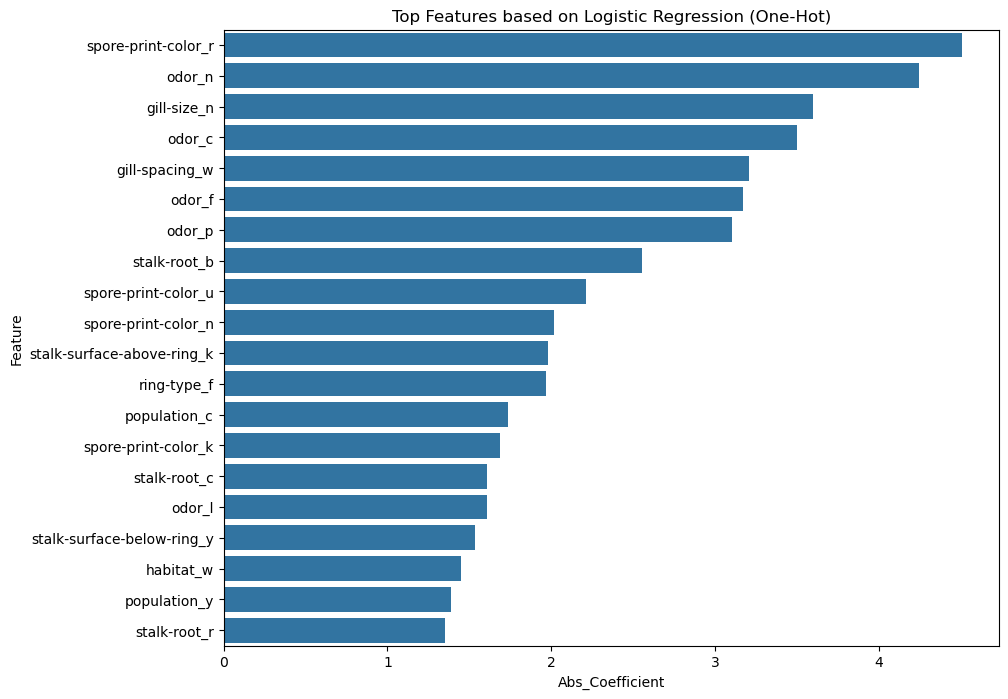

In [33]:
logistic_regression_chart(log_df_sorted)

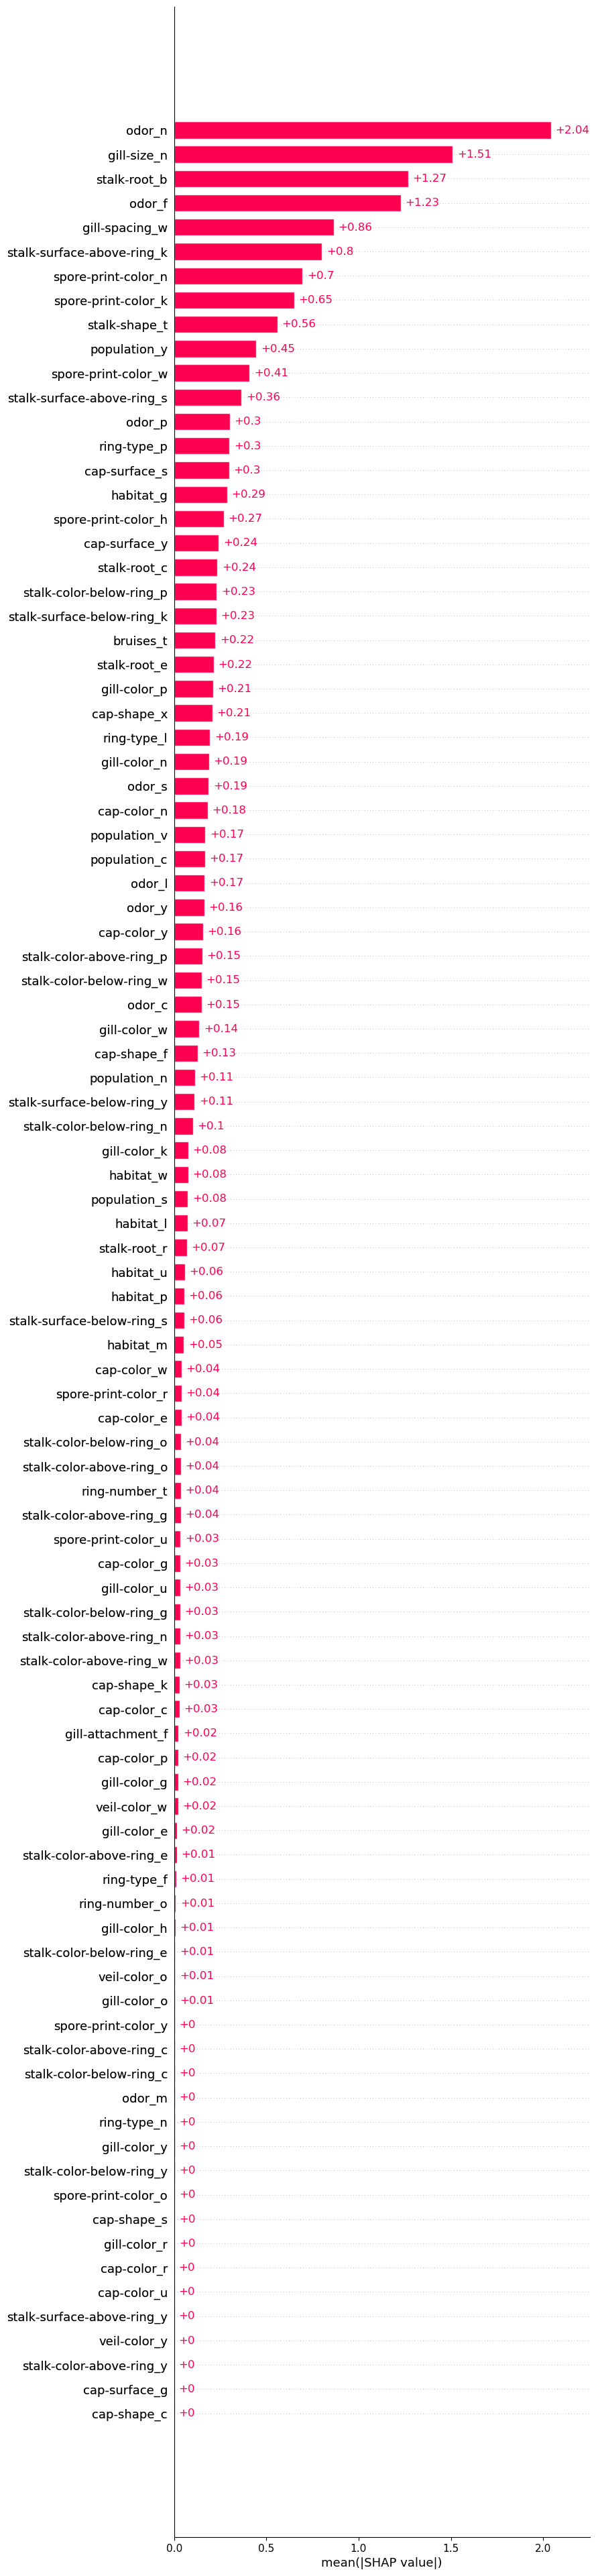

In [34]:
shap_chart(shap_values, 96)
